#Rain in Australia Prediction

### 1. Data Cleaning and Overview

#### 1.1 Import Library

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, RocCurveDisplay)
from xgboost import XGBClassifier

#### 1.2 Load Data

In [ ]:
df = pd.read_csv("weatherAUS.csv")
print(df.shape)
df.info()
df.head()

(145460, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       8

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


#### 1.3 Missing values, duplikat, unique values kategorikal

In [ ]:
miss = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
print(miss[miss > 0])
print("Duplikat:", df.duplicated().sum())
for col in df.select_dtypes(exclude="number").columns:
    print(col, "->", df[col].nunique(), "unik")
print(df["Date"].min(), "s/d", df["Date"].max())

Sunshine         48.0
Evaporation      43.2
Cloud3pm         40.8
Cloud9am         38.4
Pressure9am      10.4
Pressure3pm      10.3
WindDir9am        7.3
WindGustSpeed     7.1
WindGustDir       7.1
Humidity3pm       3.1
WindDir3pm        2.9
Temp3pm           2.5
Rainfall          2.2
RainTomorrow      2.2
RainToday         2.2
WindSpeed3pm      2.1
Humidity9am       1.8
WindSpeed9am      1.2
Temp9am           1.2
MinTemp           1.0
MaxTemp           0.9
dtype: float64
Duplikat: 0
Date -> 3436 unik
Location -> 49 unik
WindGustDir -> 16 unik
WindDir9am -> 16 unik
WindDir3pm -> 16 unik
RainToday -> 2 unik
RainTomorrow -> 2 unik
2007-11-01 s/d 2017-06-25


#### 1.4 Data Cleaning

In [ ]:
df = df.dropna(subset=["RainTomorrow"]).copy()          # baris tanpa target tidak bisa dipakai
df["RainTomorrow"] = df["RainTomorrow"].map({"No": 0, "Yes": 1})
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df = df.drop(columns="Date")
df = df.drop_duplicates()
print(df.shape)
print(df["RainTomorrow"].value_counts(normalize=True).round(3))

(142162, 23)
RainTomorrow
0    0.776
1    0.224
Name: proportion, dtype: float64


### 2. Exploratory Data Analysis (EDA)

#### 2.1 Distribusi Target dan Missing Value

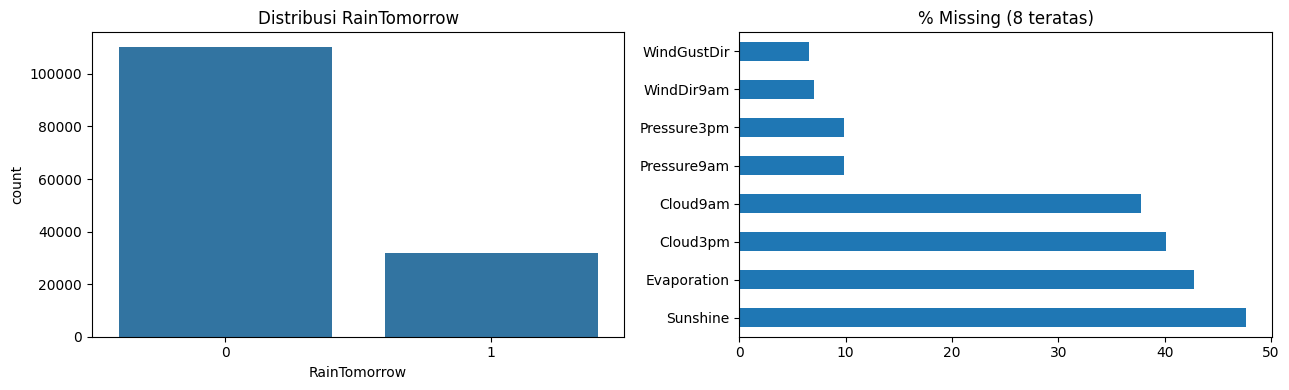

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x="RainTomorrow", data=df, ax=axes[0]); axes[0].set_title("Distribusi RainTomorrow")
(df.isnull().mean() * 100).sort_values(ascending=False).head(8).plot(kind="barh", ax=axes[1])
axes[1].set_title("% Missing (8 teratas)")
plt.tight_layout(); plt.show()

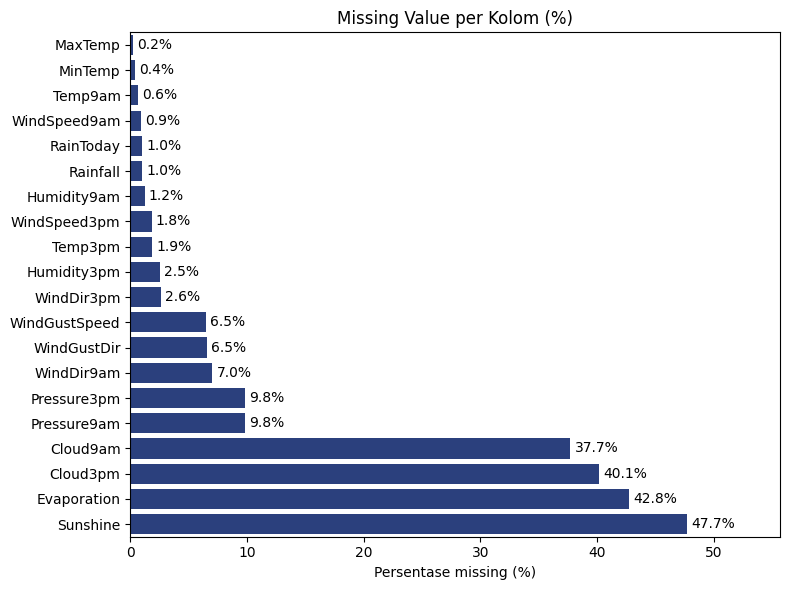

In [ ]:
miss = (df.isnull().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0].sort_values()

plt.figure(figsize=(8, 6))
ax = sns.barplot(x=miss.values, y=miss.index, color="#1E3A8A")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Missing Value per Kolom (%)")
plt.xlabel("Persentase missing (%)"); plt.ylabel("")
plt.xlim(0, miss.max() + 8)    # ruang untuk label angka
plt.tight_layout(); plt.show()

#### 2.2 Distribusi Numerik Utama vs Target

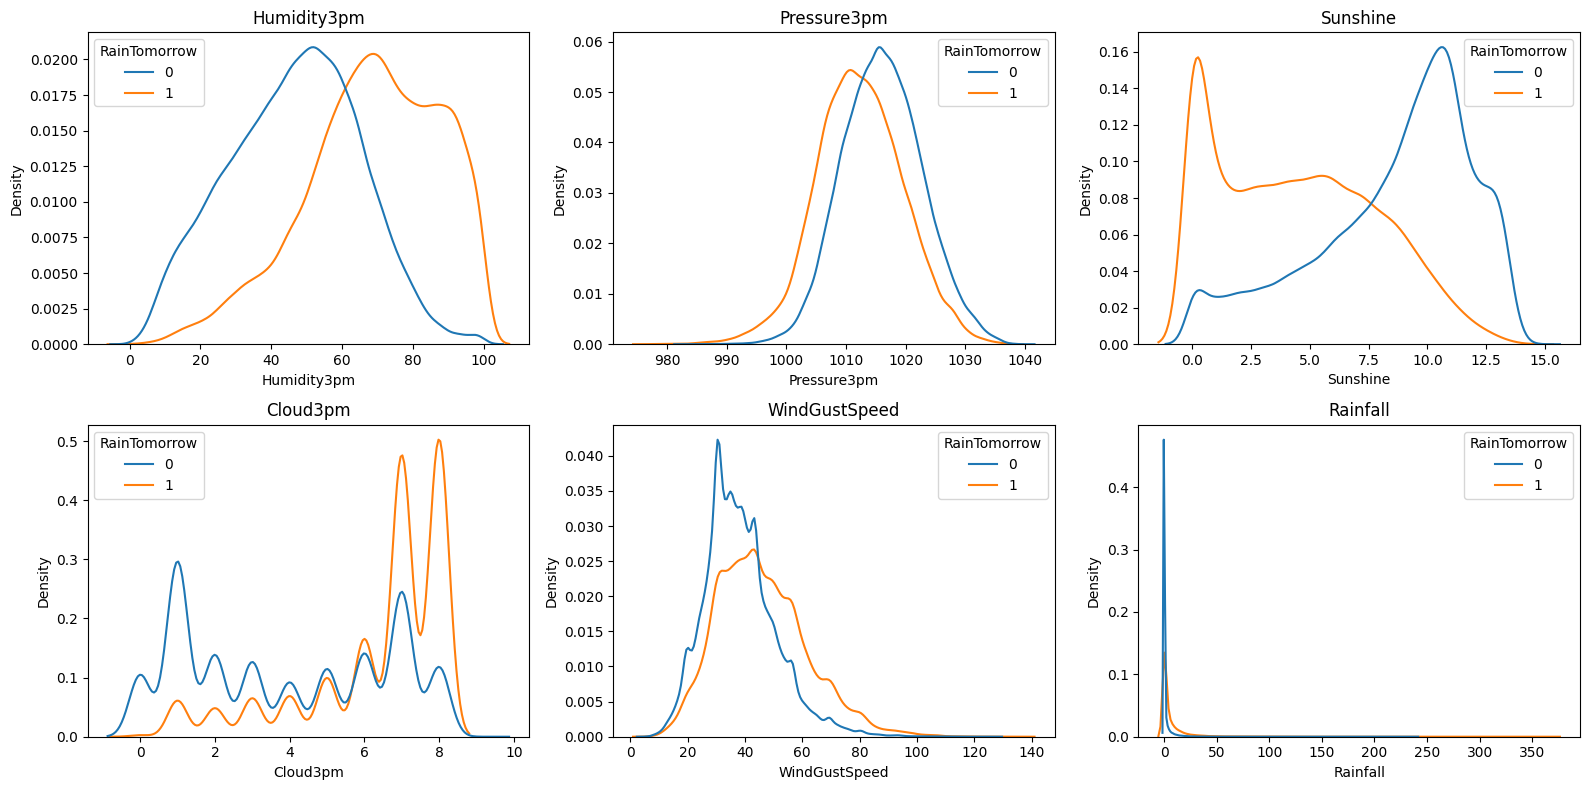

In [ ]:
cols = ["Humidity3pm", "Pressure3pm", "Sunshine", "Cloud3pm", "WindGustSpeed", "Rainfall"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cols):
    sns.kdeplot(data=df, x=c, hue="RainTomorrow", common_norm=False, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

#### 2.3 Boxplot Outlier

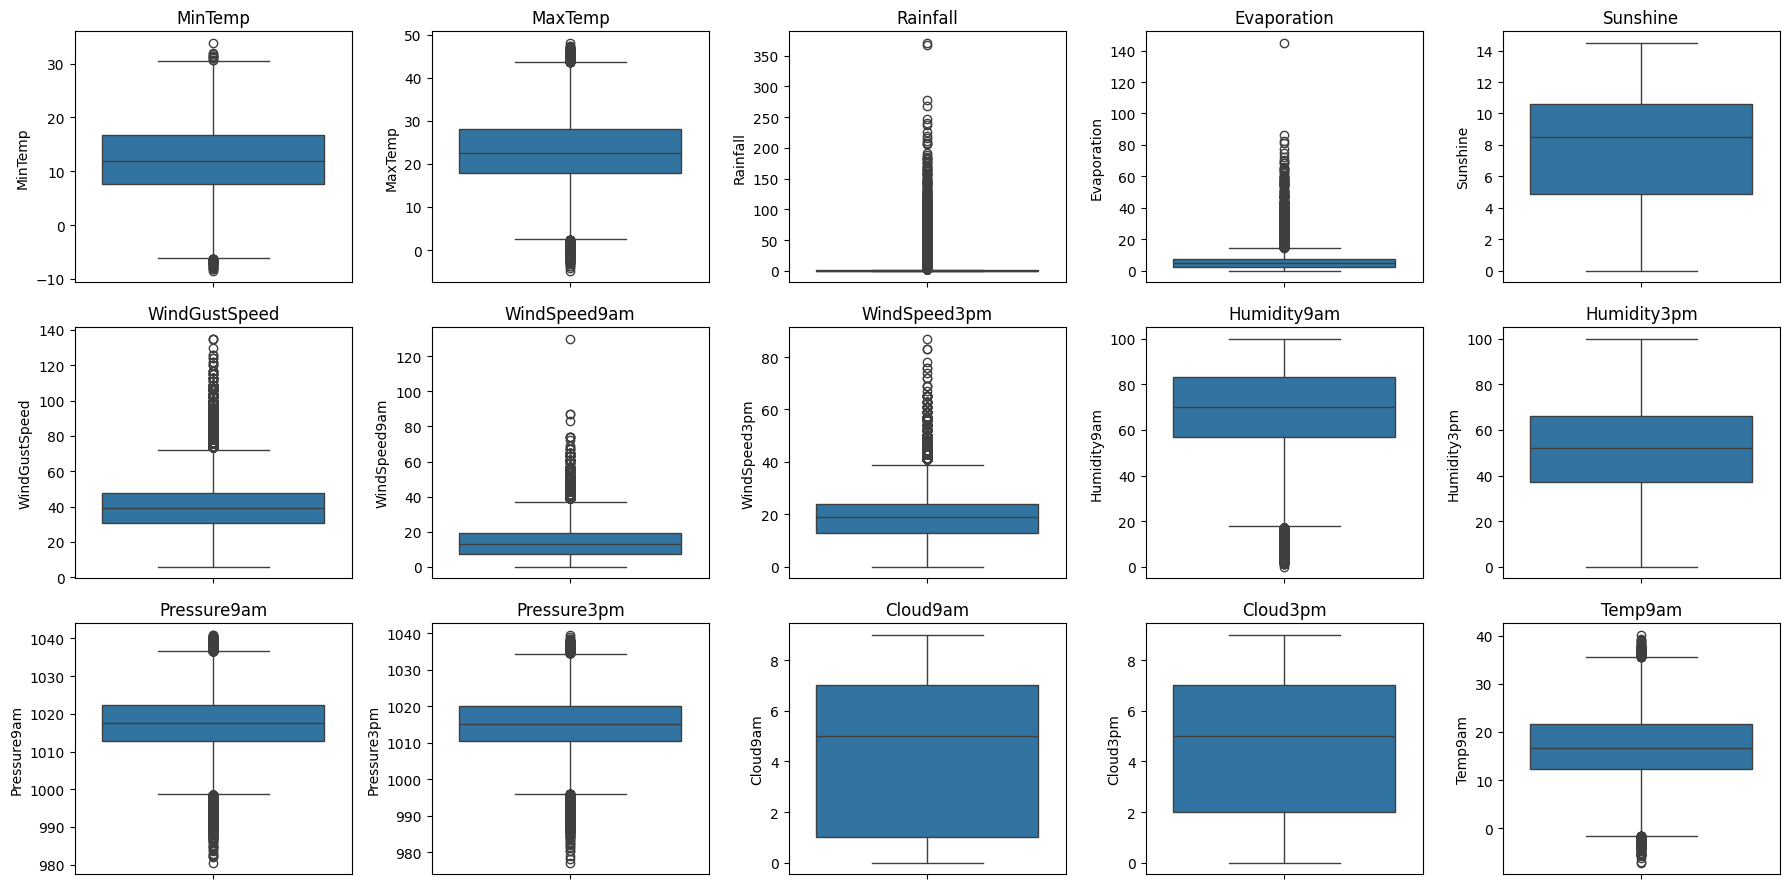

In [ ]:
num_cols = df.select_dtypes("number").drop(columns=["RainTomorrow", "Month"]).columns
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

#### 2.4 Rain Rate per Category

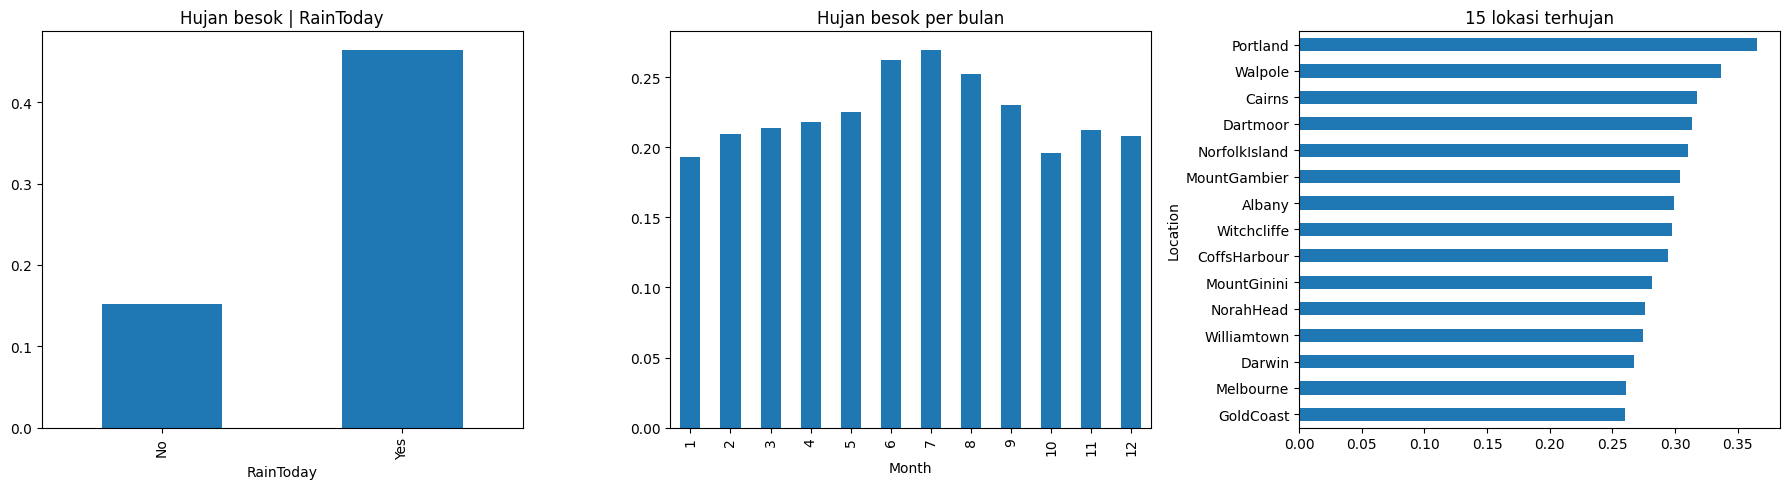

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df.groupby("RainToday")["RainTomorrow"].mean().plot(kind="bar", ax=axes[0], title="Hujan besok | RainToday")
df.groupby("Month")["RainTomorrow"].mean().plot(kind="bar", ax=axes[1], title="Hujan besok per bulan")
df.groupby("Location")["RainTomorrow"].mean().sort_values().tail(15).plot(kind="barh", ax=axes[2],
                                                                           title="15 lokasi terhujan")
plt.tight_layout(); plt.show()

#### 2.5 Correlation

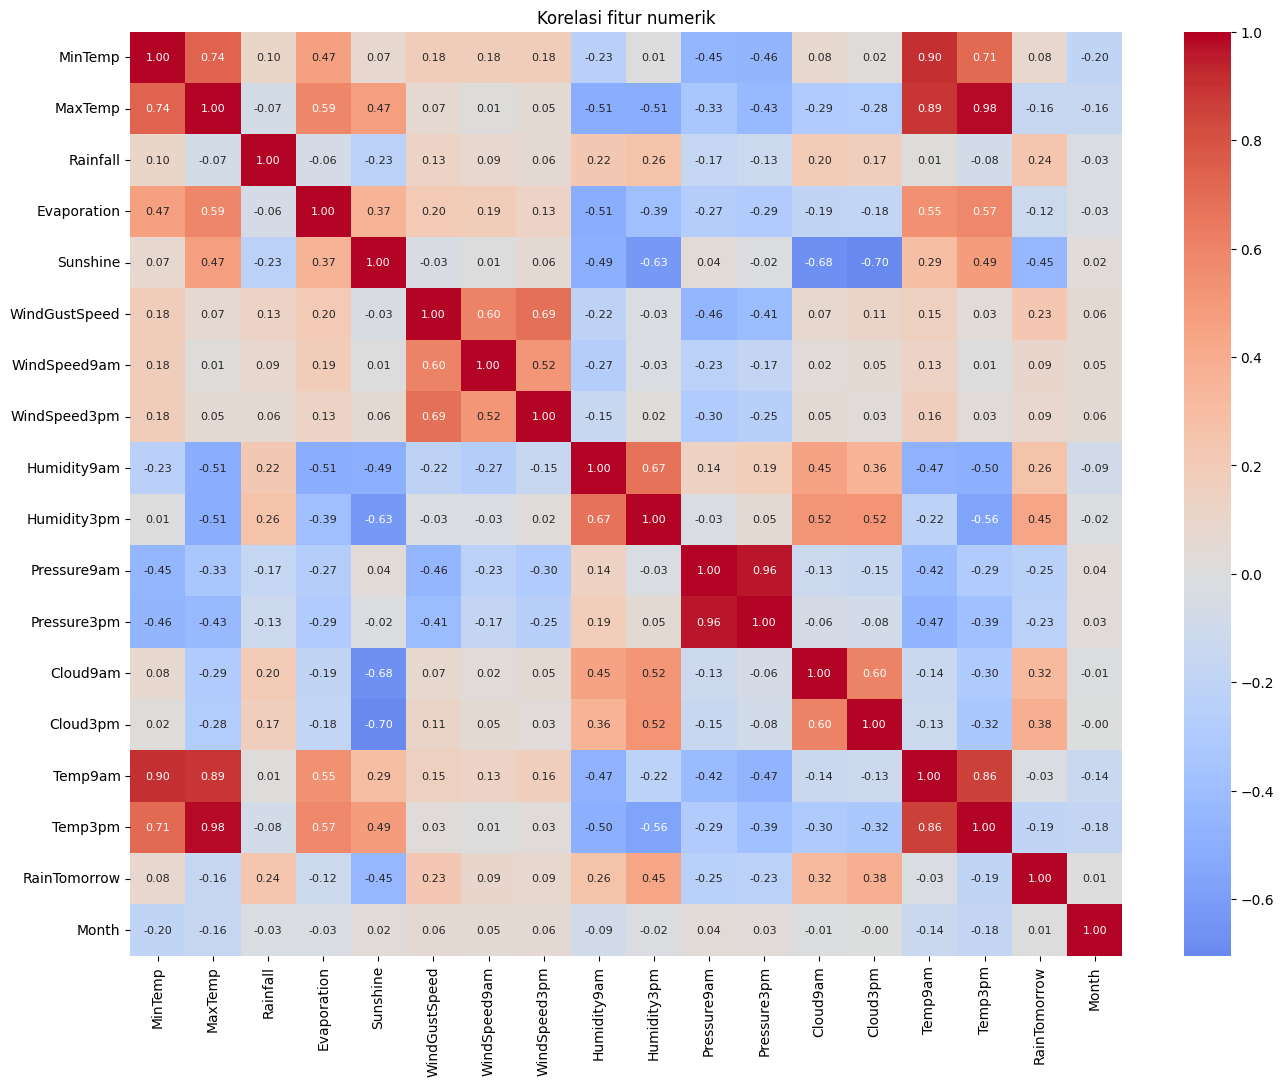

Sunshine        -0.451
Pressure9am     -0.246
Pressure3pm     -0.226
Temp3pm         -0.192
MaxTemp         -0.159
Evaporation     -0.119
Temp9am         -0.026
Month            0.007
MinTemp          0.084
WindSpeed3pm     0.088
WindSpeed9am     0.091
WindGustSpeed    0.234
Rainfall         0.239
Humidity9am      0.257
Cloud9am         0.317
Cloud3pm         0.382
Humidity3pm      0.446
RainTomorrow     1.000
Name: RainTomorrow, dtype: float64


In [ ]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Korelasi fitur numerik"); plt.show()
print(df.select_dtypes("number").corr()["RainTomorrow"].sort_values().round(3))

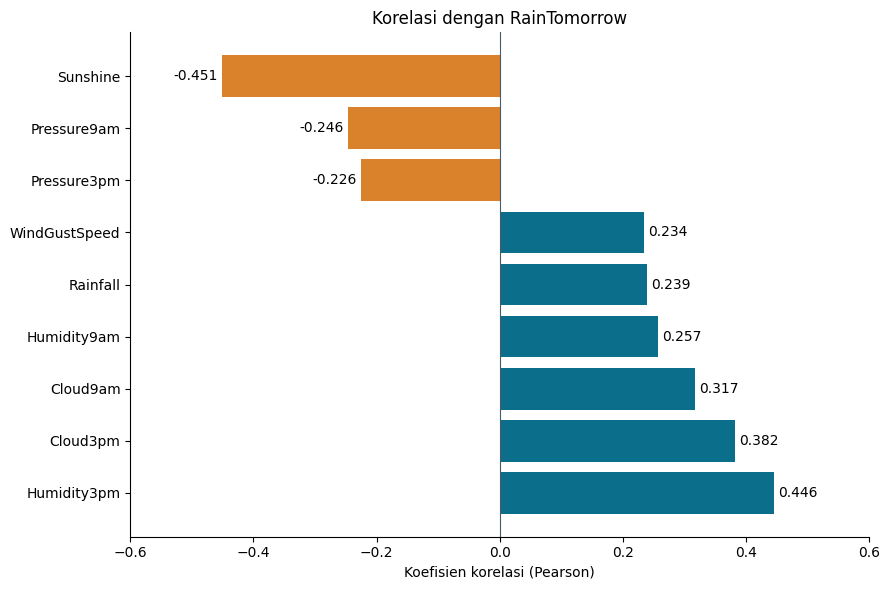

In [ ]:
# Grafik EDA: korelasi fitur numerik dengan RainTomorrow
fitur = ["Sunshine", "Pressure9am", "Pressure3pm", "Humidity9am", "Rainfall",
         "WindGustSpeed", "Cloud9am", "Cloud3pm", "Humidity3pm"]

corr = df[fitur + ["RainTomorrow"]].corr()["RainTomorrow"].drop("RainTomorrow").sort_values()
warna = ["#D9822B" if v < 0 else "#0B6E8A" for v in corr.values]   # oranye = negatif, biru = positif

plt.figure(figsize=(9, 6))
ax = plt.gca()
ax.barh(corr.index, corr.values, color=warna)
ax.invert_yaxis()                                # korelasi terendah di atas, seperti di slide
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.axvline(0, color="#4A5A66", linewidth=0.8)
ax.set_xlim(-0.6, 0.6)                           # ruang untuk label angka
ax.set_title("Korelasi dengan RainTomorrow")
ax.set_xlabel("Koefisien korelasi (Pearson)")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

### 3. Feature Engineering

#### 3.1 Fungsi Feature Engineering disimpan di file agar bisa di-load saat deployment

In [ ]:
%%writefile features.py
import numpy as np
import pandas as pd

CAT_FILL = ["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

def add_features(X):
    X = X.copy()
    X["temp_range"] = X["MaxTemp"] - X["MinTemp"]
    X["temp_change"] = X["Temp3pm"] - X["Temp9am"]
    X["humidity_change"] = X["Humidity3pm"] - X["Humidity9am"]
    X["pressure_change"] = X["Pressure3pm"] - X["Pressure9am"]
    X["wind_speed_change"] = X["WindSpeed3pm"] - X["WindSpeed9am"]
    X["log_rainfall"] = np.log1p(X["Rainfall"])
    X["month_sin"] = np.sin(2 * np.pi * X["Month"] / 12)
    X["month_cos"] = np.cos(2 * np.pi * X["Month"] / 12)
    # Australia = belahan bumi selatan
    X["Season"] = X["Month"].map({12: "Summer", 1: "Summer", 2: "Summer",
                                  3: "Autumn", 4: "Autumn", 5: "Autumn",
                                  6: "Winter", 7: "Winter", 8: "Winter",
                                  9: "Spring", 10: "Spring", 11: "Spring"})
    for c in CAT_FILL:
        X[c] = X[c].fillna("Unknown").astype(str)
    return X

Overwriting features.py


#### 3.2 Aplikasikan dan Cek Hasil

In [ ]:
from features import add_features
X = df.drop(columns="RainTomorrow")
y = df["RainTomorrow"]
new_cols = ["temp_range", "temp_change", "humidity_change", "pressure_change",
            "wind_speed_change", "log_rainfall", "Season"]
fe = add_features(X)
print(fe[new_cols].head())
print(fe.assign(y=y.values)[new_cols[:-2] + ["y"]].corr()["y"].round(3))

   temp_range  temp_change  humidity_change  pressure_change  \
0         9.5          4.9            -49.0             -0.6   
1        17.7          7.1            -19.0             -2.8   
2        12.8          2.2             -8.0              1.1   
3        18.8          8.4            -29.0             -4.8   
4        14.8         11.9            -49.0             -4.8   

   wind_speed_change  log_rainfall  Season  
0                4.0      0.470004  Summer  
1               18.0      0.000000  Summer  
2                7.0      0.000000  Summer  
3               -2.0      0.000000  Summer  
4               13.0      0.693147  Summer  
temp_range          -0.338
temp_change         -0.328
humidity_change      0.268
pressure_change      0.080
wind_speed_change   -0.004
y                    1.000
Name: y, dtype: float64


### 4. Modelling & Evaluation

#### 4.1 Split & preprocessing

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

fe_train = add_features(X_train)
num_features = fe_train.select_dtypes(include="number").columns.tolist()
cat_features = fe_train.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

def make_pipe(model):
    return Pipeline([("fe", FunctionTransformer(add_features)),
                     ("prep", preprocess),
                     ("model", model)])

#### 4.2 Latih beberapa model (class imbalance ditangani lewat class_weight / scale_pos_weight)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
models = {
    "LogReg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    "RandomForest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                           n_jobs=-1, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                   max_depth=4, subsample=0.8, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=5,
                             scale_pos_weight=neg/pos, tree_method="hist",
                             eval_metric="logloss", n_jobs=-1, random_state=42),
}

# GradientBoosting sklearn tidak punya class_weight, jadi imbalance ditangani lewat sample_weight
sw = compute_sample_weight("balanced", y_train)

pipes = {}
for name, m in models.items():
    p = make_pipe(m)
    if name == "GradientBoosting":
        p.fit(X_train, y_train, model__sample_weight=sw)
    else:
        p.fit(X_train, y_train)
    pipes[name] = p
    print("selesai:", name)

selesai: LogReg
selesai: KNN
selesai: RandomForest
selesai: GradientBoosting
selesai: XGBoost


#### 4.3 Evaluasi di Test Set

In [ ]:
rows = []
for name, p in pipes.items():
    pred, proba = p.predict(X_test), p.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, proba),
                 "pr_auc": average_precision_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.799,0.535,0.781,0.635,0.879,0.715
KNN,0.852,0.769,0.484,0.594,0.871,0.688
RandomForest,0.857,0.791,0.496,0.609,0.893,0.746
GradientBoosting,0.814,0.560,0.793,0.657,0.894,0.753
XGBoost,0.821,0.573,0.794,0.666,0.899,0.762


#### 4.4 Confusion Matrix & ROC

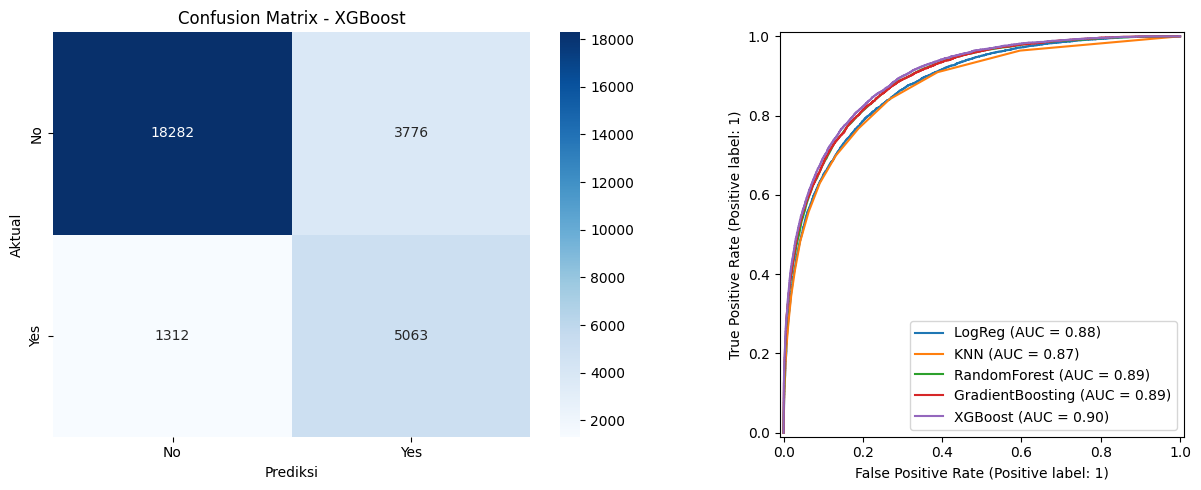

              precision    recall  f1-score   support

          No       0.93      0.83      0.88     22058
         Yes       0.57      0.79      0.67      6375

    accuracy                           0.82     28433
   macro avg       0.75      0.81      0.77     28433
weighted avg       0.85      0.82      0.83     28433



In [ ]:
best_name = results["roc_auc"].idxmax()
best_pipe = pipes[best_name]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(y_test, best_pipe.predict(X_test)), annot=True, fmt="d",
            cmap="Blues", ax=axes[0], xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
axes[0].set_title(f"Confusion Matrix - {best_name}")
axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual")
for name, p in pipes.items():
    RocCurveDisplay.from_estimator(p, X_test, y_test, name=name, ax=axes[1])
plt.tight_layout(); plt.show()
print(classification_report(y_test, best_pipe.predict(X_test), target_names=["No", "Yes"]))

### 5. Overfitting & Feature Selection

#### 5.1 Gap train vs test

In [ ]:
gap = []
for name, p in pipes.items():
    gap.append({"model": name,
                "train_auc": roc_auc_score(y_train, p.predict_proba(X_train)[:, 1]),
                "test_auc": roc_auc_score(y_test, p.predict_proba(X_test)[:, 1])})
gap = pd.DataFrame(gap).set_index("model")
gap["gap"] = gap["train_auc"] - gap["test_auc"]
gap.round(3)

,train_auc,test_auc,gap
model,,,
LogReg,0.877,0.879,-0.002
KNN,0.913,0.871,0.042
RandomForest,1.000,0.893,0.107
GradientBoosting,0.903,0.894,0.009
XGBoost,0.923,0.899,0.024


#### 5.2 Cross-validation

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_rows = []
for name, m in models.items():
    if name == "KNN":
        continue   # KNN sangat lambat di CV (data besar, fitur banyak); lewati
    fit_params = {"model__sample_weight": sw} if name == "GradientBoosting" else None
    s = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=["roc_auc", "f1"],
                       return_train_score=True, params=fit_params)
    cv_rows.append({"model": name,
                    "train_auc": s["train_roc_auc"].mean(),
                    "val_auc": s["test_roc_auc"].mean(),
                    "val_auc_std": s["test_roc_auc"].std(),
                    "val_f1": s["test_f1"].mean()})
pd.DataFrame(cv_rows).set_index("model").round(3)

,train_auc,val_auc,val_auc_std,val_f1
model,,,,
LogReg,0.877,0.875,0.001,0.634
RandomForest,1.000,0.890,0.002,0.597
GradientBoosting,0.908,0.890,0.002,0.654
XGBoost,0.932,0.895,0.002,0.663


#### 5.3 Mengurangi Overfitting: Tuning XGBoost (Regularization & Tree Depth)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from features import add_features

def make_pipe(model):
    return Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("prep", preprocess),
        ("model", model)
    ])

param_dist = {
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__n_estimators": [200, 300, 500],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda": [1, 5, 10],
}

search = RandomizedSearchCV(make_pipe(models["XGBoost"]), param_dist, n_iter=15,
                            scoring="roc_auc", cv=cv, random_state=42, verbose=1)
search.fit(X_train, y_train)
tuned = search.best_estimator_
print("Best params:", search.best_params_)
print("CV AUC   :", round(search.best_score_, 3))
print("Train AUC:", round(roc_auc_score(y_train, tuned.predict_proba(X_train)[:, 1]), 3))
print("Test AUC :", round(roc_auc_score(y_test, tuned.predict_proba(X_test)[:, 1]), 3))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best params: {'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.6}
CV AUC   : 0.898
Train AUC: 0.933
Test AUC : 0.902


#### 5.4 Feature Importance

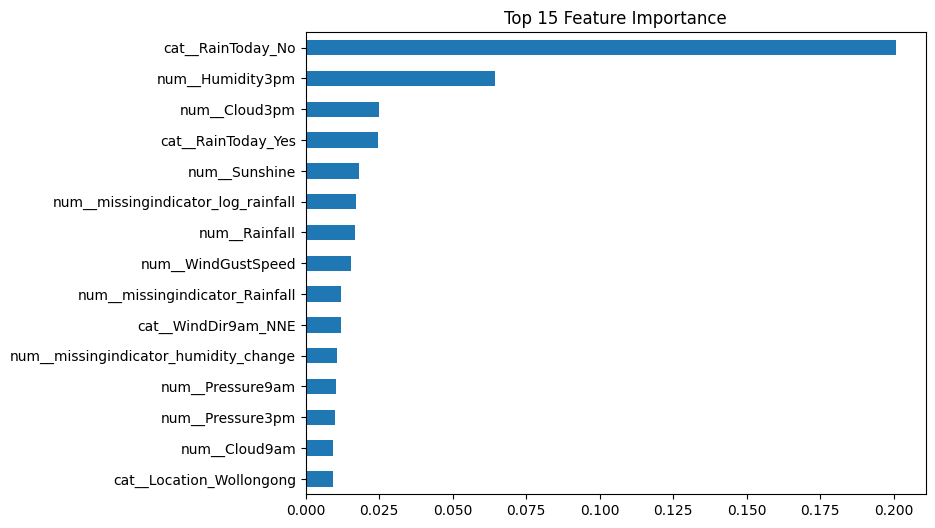

In [ ]:
feat_names = tuned.named_steps["prep"].get_feature_names_out()
imp = pd.Series(tuned.named_steps["model"].feature_importances_, index=feat_names)
imp.sort_values().tail(15).plot(kind="barh", figsize=(8, 6), title="Top 15 Feature Importance")
plt.show()

#### 5.5 Feature Selection

In [ ]:
best_xgb_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
selector_pipe = Pipeline([
    ("fe", FunctionTransformer(add_features)),
    ("prep", preprocess),
    ("select", SelectFromModel(XGBClassifier(n_estimators=100, tree_method="hist", n_jobs=-1,
                                             random_state=42), threshold="median")),
    ("model", XGBClassifier(**best_xgb_params, scale_pos_weight=neg/pos, tree_method="hist",
                            eval_metric="logloss", n_jobs=-1, random_state=42)),
])
selector_pipe.fit(X_train, y_train)
n_kept = selector_pipe.named_steps["select"].get_support().sum()
print(f"Fitur dipakai: {n_kept} dari {len(feat_names)}")
print("Test AUC (selected):", round(roc_auc_score(y_test, selector_pipe.predict_proba(X_test)[:, 1]), 3))
print("Test AUC (full)    :", round(roc_auc_score(y_test, tuned.predict_proba(X_test)[:, 1]), 3))

Fitur dipakai: 77 dari 154
Test AUC (selected): 0.9
Test AUC (full)    : 0.902


### 6. Deployment & Streamlit

#### 6.1 Simpan Model Final & Metadata Untuk Dropdown di App

In [ ]:
import joblib
final_model = tuned   # ganti ke selector_pipe jika AUC-nya sebanding dengan fitur lebih sedikit
joblib.dump(final_model, "rain_model.joblib")

meta = {
    "locations": sorted(df["Location"].unique().tolist()),
    "wind_dirs": sorted(df["WindGustDir"].dropna().unique().tolist()),
    "medians": X_train.median(numeric_only=True).round(1).to_dict(),
}
joblib.dump(meta, "meta.joblib")
print("Tersimpan: rain_model.joblib & meta.joblib")

Tersimpan: rain_model.joblib & meta.joblib


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
from features import add_features   # wajib ada agar pipeline bisa di-load

model = joblib.load("rain_model.joblib")
meta = joblib.load("meta.joblib")
med = meta["medians"]
winds = meta["wind_dirs"]

st.title("Prediksi Hujan Besok di Australia")
st.caption("Model klasifikasi (XGBoost) berdasarkan data cuaca hari ini")

c1, c2 = st.columns(2)
with c1:
    location = st.selectbox("Lokasi", meta["locations"])
    month = st.slider("Bulan", 1, 12, 6)
    rain_today = st.selectbox("Hujan hari ini?", ["No", "Yes"])
    min_temp = st.number_input("MinTemp (°C)", value=med["MinTemp"])
    max_temp = st.number_input("MaxTemp (°C)", value=med["MaxTemp"])
    rainfall = st.number_input("Rainfall (mm)", min_value=0.0, value=0.0)
    evap = st.number_input("Evaporation (mm)", min_value=0.0, value=med["Evaporation"])
    sunshine = st.number_input("Sunshine (jam)", min_value=0.0, value=med["Sunshine"])
    gust_dir = st.selectbox("WindGustDir", winds)
    gust_speed = st.number_input("WindGustSpeed (km/h)", min_value=0.0, value=med["WindGustSpeed"])
with c2:
    dir9 = st.selectbox("WindDir9am", winds)
    dir3 = st.selectbox("WindDir3pm", winds)
    ws9 = st.number_input("WindSpeed9am (km/h)", min_value=0.0, value=med["WindSpeed9am"])
    ws3 = st.number_input("WindSpeed3pm (km/h)", min_value=0.0, value=med["WindSpeed3pm"])
    h9 = st.slider("Humidity9am (%)", 0, 100, int(med["Humidity9am"]))
    h3 = st.slider("Humidity3pm (%)", 0, 100, int(med["Humidity3pm"]))
    p9 = st.number_input("Pressure9am (hPa)", value=med["Pressure9am"])
    p3 = st.number_input("Pressure3pm (hPa)", value=med["Pressure3pm"])
    cl9 = st.slider("Cloud9am (oktas)", 0, 9, int(med["Cloud9am"]))
    cl3 = st.slider("Cloud3pm (oktas)", 0, 9, int(med["Cloud3pm"]))
    t9 = st.number_input("Temp9am (°C)", value=med["Temp9am"])
    t3 = st.number_input("Temp3pm (°C)", value=med["Temp3pm"])

if st.button("Prediksi"):
    row = pd.DataFrame([{
        "Location": location, "MinTemp": min_temp, "MaxTemp": max_temp, "Rainfall": rainfall,
        "Evaporation": evap, "Sunshine": sunshine, "WindGustDir": gust_dir,
        "WindGustSpeed": gust_speed, "WindDir9am": dir9, "WindDir3pm": dir3,
        "WindSpeed9am": ws9, "WindSpeed3pm": ws3, "Humidity9am": h9, "Humidity3pm": h3,
        "Pressure9am": p9, "Pressure3pm": p3, "Cloud9am": cl9, "Cloud3pm": cl3,
        "Temp9am": t9, "Temp3pm": t3, "RainToday": rain_today, "Month": month}])
    proba = model.predict_proba(row)[0, 1]
    st.metric("Probabilitas hujan besok", f"{proba:.1%}")
    st.progress(float(proba))
    if proba >= 0.5:
        st.error("Besok kemungkinan HUJAN, bawa payung.")
    else:
        st.success("Besok kemungkinan TIDAK hujan.")

Writing app.py
